In [2]:
from rdkit import Chem
import os
from rdkit.Chem.Draw import IPythonConsole
ptable = Chem.GetPeriodicTable()
electronegativity_dict = {1: 2.2,
 3: 0.98,
 4: 1.57,
 5: 2.04,
 6: 2.55,
 7: 3.04,
 8: 3.44,
 9: 3.98,
 11: 0.93,
 12: 1.31,
 13: 1.61,
 14: 1.9,
 15: 2.19,
 16: 2.58,
 17: 3.16,
 19: 0.82,
 20: 1.0,
 21: 1.36,
 22: 1.54,
 23: 1.63,
 24: 1.66,
 25: 1.55,
 26: 1.83,
 27: 1.88,
 28: 1.91,
 29: 1.9,
 30: 1.65,
 31: 1.81,
 32: 2.01,
 33: 2.18,
 34: 2.55,
 35: 2.96,
 36: 3.0,
 37: 0.82,
 38: 0.95,
 39: 1.22,
 40: 1.33,
 41: 1.6,
 42: 2.16,
 43: 1.9,
 44: 2.2,
 45: 2.28,
 46: 2.2,
 47: 1.93,
 48: 1.69,
 49: 1.78,
 50: 1.96,
 51: 2.05,
 52: 2.1,
 53: 2.66}


In [3]:
"""
Rule 1: Identify pi and pi* and lone pair and empty orbital as source and sinks
Rule 2: Identify suitable leaving groups (suitable sigma star)
Rule 2.5: Identify reactive sigma bonds
Rule 3: Identify acidic hydrogens
"""

'\nRule 1: Identify pi and pi* and lone pair and empty orbital as source and sinks\nRule 2: Identify suitable leaving groups (suitable sigma star)\nRule 2.5: Identify reactive sigma bonds\nRule 3: Identify acidic hydrogens\n'

In [4]:
cat_and_brom = Chem.MolFromSmiles(r'C[C+](C)C.[Br-]')
tert_brom = Chem.MolFromSmiles('CC(C)(Br)C')

In [5]:
def identify_source(mol, rules = "all"):
    for bond in mol.GetBonds():
        # Conditional on rules being on
        if rules == 'all':
            if bond.GetBondTypeAsDouble() == 1:
                # For any element less electronegative than boron (inclusive) - add sigma bond as source - going from more electronegative atom
                if electronegativity_dict[bond.GetBeginAtom().GetAtomicNum()] < 2.05:
                    bond.GetEndAtom().SetProp('source', 'sigma bond')
                    bond.SetProp('source', 'sigma bond')
                if electronegativity_dict[bond.GetEndAtom().GetAtomicNum()] < 2.05:
                    bond.GetBeginAtom().SetProp('source', 'sigma bond')
                    bond.SetProp('source', 'sigma bond')
        # Looking for double and triple bonds - ignoring aromatic systems
        if bond.GetBondTypeAsDouble() > 1.5:
            bond.SetProp('source', 'pi bond')
            atom1 = bond.GetBeginAtom()
            atom2 = bond.GetEndAtom()
            # if bond is homonuclear then either atom can be source
            if atom1.GetAtomicNum() == atom2.GetAtomicNum():
                atom1.SetProp('source', 'pi bond')
                atom2.SetProp('source', 'pi bond')
            else:
                # if bond is heteronuclear then the more electronegative atom is source
                if electronegativity_dict[atom1.GetAtomicNum()] < electronegativity_dict[atom2.GetAtomicNum()]:
                    atom2.SetProp('source', 'pi bond')
                else:
                    atom1.SetProp('source', 'pi bond')
    # This loop coming after the bond loop ensures that all molecules with lone pairs react via the lone pair instead of a pi bond
    for atom in mol.GetAtoms():
        # Look for hydrides - M-H bond
        if electronegativity_dict[atom.GetAtomicNum()] < 2.05 and atom.GetFormalCharge() < 0 and atom.GetNumExplicitHs() > 0:
            atom.SetProp('source', 'hydride')
        valence_electrons = ptable.GetNOuterElecs(atom.GetAtomicNum())
        lone_electrons = valence_electrons - atom.GetTotalValence() - atom.GetFormalCharge()
        if lone_electrons > 0:
            atom.SetProp('source', 'lone pair')
        
        

In [16]:
def identify_sink(mol, rules = "all"):
    for bond in mol.GetBonds():
        
        # Conditional on all rules being swtiched on
        if rules == "all":
            # Identify possible sigma stars by considering leaving groups being any element that has a higher electronegativity than carbon
            if bond.GetBondTypeAsDouble() == 1:
                if electronegativity_dict[bond.GetEndAtom().GetAtomicNum()] > 2.55:
                    bond.SetProp('sink', 'sigma star')
                    #Set the other atom connected to this leaving group as the electron sink
                    bond.GetBeginAtom().SetProp('sink', 'sigma star')
                # Repeat for the other atom in a bond. Note e.g. N-N would be possible to attack at each end
                if electronegativity_dict[bond.GetBeginAtom().GetAtomicNum()] > 2.55:
                    bond.SetProp('sink', 'sigma star')
                    bond.GetEndAtom().SetProp('sink', 'sigma star')
                    bond.GetEndAtom().SetProp('sink', 'sigma star')
        if bond.GetBondTypeAsDouble() > 1.5:
            bond.SetProp('sink', 'pi star')
            atom1 = bond.GetBeginAtom()
            atom2 = bond.GetEndAtom()
            if atom1.GetAtomicNum() == atom2.GetAtomicNum():
                atom1.SetProp('sink', 'pi star')
                atom2.SetProp('sink', 'pi star')
            else:
                if electronegativity_dict[atom1.GetAtomicNum()] > electronegativity_dict[atom2.GetAtomicNum()]:
                    atom2.SetProp('sink', 'pi star')
                else:
                    atom1.SetProp('sink', 'pi star')
    # Likewise as above, this loop coming second ensures that empty orbitals are attacked in place of a pi star where an atom might have both
    for atom in mol.GetAtoms():
        valence_electrons = ptable.GetNOuterElecs(atom.GetAtomicNum())
        lone_electrons = valence_electrons - atom.GetTotalValence() - atom.GetFormalCharge()
        num_bond_electrons = atom.GetTotalValence()*2
        # this may only be valid for the first few rows of the periodic table
        if lone_electrons + num_bond_electrons < 8 and atom.GetAtomicNum() != 1:
            atom.SetProp('sink', 'empty AO')
        #Special case for H
        if atom.GetAtomicNum() == 1 and lone_electrons + num_bond_electrons < 2:
            atom.SetProp('sink', 'empty AO')

In [17]:
def prepare_molecule(mol):
    identify_sink(mol)
    identify_source(mol)
    return None

In [18]:
acetophenone = Chem.MolFromSmiles('CC(=O)C1=CC=CC=C1')
cyanide = Chem.MolFromSmiles('[C-]#N')
ethylbromide = Chem.MolFromSmiles('CCBr')
iodide = Chem.MolFromSmiles('[I-]')

In [19]:
identify_sink(cyanide)
identify_source(cyanide)
identify_sink(ethylbromide)
identify_source(acetophenone)

In [20]:
def b_to_a(mol, i, j):
    bond = mol.GetBondBetweenAtoms(i,j)
    bond_order = int(bond.GetBondTypeAsDouble())
    a_l = mol.GetAtomWithIdx(i)
    c = a_l.GetFormalCharge()
    a_l.SetFormalCharge(c+1)
    a_b = mol.GetAtomWithIdx(j)
    c = a_b.GetFormalCharge()
    a_b.SetFormalCharge(c-1)
    e_mol = Chem.EditableMol(mol)
    e_mol.RemoveBond(i,j)
    if bond_order != 1:
        e_mol.AddBond(i,j, order=Chem.BondType.values[bond_order-1])
    return e_mol.GetMol()

def a_to_b(mol, i, j):
    bond = mol.GetBondBetweenAtoms(i,j)
    a_l = mol.GetAtomWithIdx(i)
    c = a_l.GetFormalCharge()
    a_l.SetFormalCharge(c+1)
    a_b = mol.GetAtomWithIdx(j)
    c = a_b.GetFormalCharge()
    a_b.SetFormalCharge(c-1)
    e_mol = Chem.EditableMol(mol)
    if not bond:
        e_mol.AddBond(i,j, order=Chem.BondType.values[1])
    else:
        e_mol.RemoveBond(i,j)
        bond_order = int(bond.GetBondTypeAsDouble())
        e_mol.AddBond(i,j, order=Chem.BondType.values[bond_order+1])
    return e_mol.GetMol()

In [21]:
def clean_mol(list_mol):
    existing_inchi = set([])
    clean_list = []
    for mol in list_mol:
        inchi = Chem.MolToInchi(mol)
        if inchi not in existing_inchi:
            existing_inchi.add(inchi)
            clean_list.append(mol)
    return clean_list

In [113]:
mol2 = Chem.MolFromSmiles('CC=C')
mol1 = Chem.MolFromSmiles('OOC(=O)C1=CC=CC=C1')
prepare_molecule(mol1)
prepare_molecule(mol2)
new_mols = []
connected_mols = []
atoms = [a for a in mol1.GetAtoms()] + [a for a in mol2.GetAtoms()]
for atom1 in atoms:
    #check if the source is a bond, to avoid errors when removing the 'make_bond' property
    bond_flag = False
    reinstate_sink = {}
    reinstate_atom_1 = False
    if atom1.HasProp('source'):
        print(atom1.GetIdx(), atom1.GetSymbol(), atom1.GetTotalValence(), atom1.GetProp('source'))            
        if atom1.GetProp('source') == 'lone pair' or atom1.GetProp('source') == 'hydride':
            atom1.SetBoolProp('make_bond', 1)
        if atom1.GetProp('source') == 'sigma bond' or atom1.GetProp('source') == 'pi bond':
            bond_flag = True
            if atom1.HasProp('sink'):
                reinstate_atom_1 = atom1.GetProp('sink')
                atom1.ClearProp('sink')
            atom1.SetBoolProp('make_bond', 1)
            for bond1 in atom1.GetBonds():
                if bond1.HasProp('source'):
                    partner_atom = bond1.GetOtherAtom(atom1)
                    #An ugly workaround where having two source bonds means only a bond that can actually be a source on the right atom is used
                    if electronegativity_dict[atom1.GetAtomicNum()] < electronegativity_dict[partner_atom.GetAtomicNum()]:
                        continue
                    if bond1.HasProp('sink'):
                        reinstate_sink[bond1.GetIdx()] = bond1.GetProp('sink')
                        bond1.ClearProp('sink')           
                    bond1.SetBoolProp('make_bond', 1)
                    #Technically there could be more than one reactive sigma bond attached to each atom; this might be implemented later
        for atom2 in atoms:
            if atom1.GetIdx() == atom2.GetIdx():
                continue
            reinstate_source = {}
            reinstate_atom_2 = False
            if atom2.HasProp('sink'):
                print(atom2.GetIdx(), atom2.GetSymbol(), atom2.GetTotalValence(), atom2.GetProp('sink'))
                if atom2.GetProp('sink') == 'empty AO':
                    atom2.SetBoolProp('make_bond', 1)
                    new_mols.append(Chem.CombineMols(mol1, mol2))
                elif atom2.GetProp('sink') == 'pi star' or atom2.GetProp('sink') == 'sigma star':
                    atom2.SetBoolProp('make_bond', 1)
                    if atom2.HasProp('source'):
                        reinstate_atom_2 = atom2.GetProp('source')
                        #print('reinstante source', atom2.GetSymbol(), atom2.GetProp('source'))
                        atom2.ClearProp('source')
                    for bond2 in atom2.GetBonds():
                        if bond2.HasProp('sink'):
                            partner_atom = bond2.GetOtherAtom(atom2)
                            #An ugly workaround where having two sink bonds means only a bond that can actually be a sink on the right atom is used
                            if electronegativity_dict[atom2.GetAtomicNum()] > electronegativity_dict[partner_atom.GetAtomicNum()]:
                                continue
                            if bond2.HasProp('source'):
                                reinstate_source[bond2.GetIdx()] = bond2.GetProp('source')
                                bond2.ClearProp('source')
                            bond2.SetBoolProp('make_bond', 1)
                            new_mols.append(Chem.CombineMols(mol1, mol2))
                            bond2.ClearProp('make_bond')
                atom2.ClearProp('make_bond')
            if reinstate_source:
                print(reinstate_source)
                for idx, bond_type in reinstate_source.items():
                    for bond in atom2.GetBonds():
                        if bond.GetIdx() == idx:
                            print(idx)
                            bond.SetProp('source', bond_type) 
                            print('reinstating source', bond.GetBeginAtomIdx(), bond.GetEndAtomIdx(), bond.GetProp('source'))
            if reinstate_atom_2:
                #print('reinstanting')
                atom2.SetProp('source', reinstate_atom_2)                        
        atom1.ClearProp('make_bond')
        # Only remove property if bond1 was defined in the first place
        if bond_flag:
            bond1.ClearProp('make_bond')
        if reinstate_sink:
            for idx, bond_type in reinstate_sink.items():
                    for bond in atom1.GetBonds():
                        if bond.GetIdx() == idx:
                            bond.SetProp('sink', bond_type)
                            print('reinstante sink',bond.GetBeginAtomIdx(), bond.GetEndAtomIdx(), bond.GetProp('sink'))
        if reinstate_atom_1:
            atom1.SetProp('sink', reinstate_atom_1)
        

counter = 0
for mol in new_mols:
    inter_mol = mol
    k = None
    l = None
    # Need to treat hydrides differently because of the way RDKit handles them
    hydride_flag = False
    bond_sink_flag = False
    flag_save = False

    for atom in mol.GetAtoms():
        if atom.HasProp('make_bond'):
            if atom.HasProp('source'):
                print('source connecting loop', atom.GetSymbol(), atom.GetProp('source'))
                # Different behaviour required for hydrides
                if atom.GetProp('source') == 'hydride':
                    hydride_flag = True
                    #Debug statement
                    #print(atom.GetSymbol(),atom.GetNumExplicitHs(), atom.GetNumImplicitHs())
                    atom.SetNumExplicitHs(atom.GetNumExplicitHs() - 1)
                    atom.SetFormalCharge(atom.GetFormalCharge() + 1)
                i = atom.GetIdx()
                if atom.GetProp('source') == 'sigma bond' or atom.GetProp('source') == 'pi bond':
                    print('breaking bond here')
                    for bond in atom.GetBonds():
                        if bond.HasProp('make_bond') and bond.HasProp('source') and bond.GetProp('source') == atom.GetProp('source'):
                            k = bond.GetOtherAtom(atom).GetIdx()
                            inter_mol = b_to_a(inter_mol, k, i)
            elif atom.HasProp('sink'):
                print('sink connecting loop', atom.GetSymbol(), atom.GetProp('sink'))
                j = atom.GetIdx()
                if atom.GetProp('sink') == 'sigma star' or atom.GetProp('sink') == 'pi star':
                    print('sink', atom.GetSymbol(), atom.GetIdx(), atom.GetProp('sink'))
                    #Debug statement
                    #if atom.GetProp('sink') == 'sigma star':
                        #for bond in atom.GetBonds():
                            #print('bonds connected to sigma star', bond.HasProp('make_bond'), bond.GetBeginAtom().GetSymbol(), bond.GetEndAtom().GetSymbol())
                            #if bond.HasProp('make_bond'):
                              #  l = bond.GetOtherAtom(atom).GetIdx()
                               # inter_mol = a_to_b(inter_mol, j, l)
                    bond_sink_flag = True
                    for bond in atom.GetBonds():
                        print(bond.GetBeginAtom().GetSymbol(), bond.GetEndAtom().GetSymbol(), bond.GetBondTypeAsDouble())
                        if bond.HasProp('make_bond') and bond.HasProp('sink') and bond.GetProp('sink') == atom.GetProp('sink'):
                            l = bond.GetOtherAtom(atom).GetIdx()
                            print('breaking bond between', atom.GetSymbol(),atom.GetIdx(), bond.GetOtherAtom(atom).GetSymbol(), bond.GetOtherAtom(atom).GetIdx())   
                            inter_mol = b_to_a(inter_mol, j, l)
                            flag_save = True
            else:
                print('something went wrong')
    if (k is not None and k == j) or (l is not None and l == i) or i == j or (bond_sink_flag and not flag_save):
        # this is will remove any 'cycles' that close in on themselves and make no net change
        continue
    if hydride_flag:
        inter_mol.GetAtomWithIdx(j).SetNumExplicitHs(inter_mol.GetAtomWithIdx(j).GetNumImplicitHs() + 1)
        inter_mol.GetAtomWithIdx(j).SetFormalCharge(inter_mol.GetAtomWithIdx(j).GetFormalCharge() - 1)
        connected_mols.append(inter_mol)
        continue
    print('making bond between', inter_mol.GetAtomWithIdx(i).GetSymbol(), i, inter_mol.GetAtomWithIdx(j).GetSymbol(), j)
    inter_mol = a_to_b(inter_mol, i, j)
    connected_mols.append(inter_mol)
    counter +=1
    print(counter, ":", Chem.MolToSmiles(inter_mol))
    
# as it stands this doesn't work for Grignards because of the way that InChI is generated
connected_mols = clean_mol(connected_mols)
    


0 O 2 lone pair
1 O 2 sigma star
2 C 4 pi star
{2: 'pi bond'}
2
reinstating source 2 3 pi bond
1 C 4 pi star
{1: 'pi bond'}
1
reinstating source 1 2 pi bond
2 C 4 pi star
{1: 'pi bond'}
1
reinstating source 1 2 pi bond
1 O 2 lone pair
0 O 2 sigma star
2 C 4 pi star
{2: 'pi bond'}
2
reinstating source 2 3 pi bond
2 C 4 pi star
{1: 'pi bond'}
1
reinstating source 1 2 pi bond
3 O 2 lone pair
0 O 2 sigma star
1 O 2 sigma star
2 C 4 pi star
{2: 'pi bond'}
2
reinstating source 2 3 pi bond
1 C 4 pi star
{1: 'pi bond'}
1
reinstating source 1 2 pi bond
2 C 4 pi star
{1: 'pi bond'}
1
reinstating source 1 2 pi bond
1 C 4 pi bond
0 O 2 sigma star
2 C 4 pi star
{2: 'pi bond'}
2
reinstating source 2 3 pi bond
2 C 4 pi star
reinstante sink 1 2 pi star
2 C 4 pi bond
0 O 2 sigma star
1 O 2 sigma star
1 C 4 pi star
reinstante sink 1 2 pi star
source connecting loop O lone pair
sink connecting loop O sigma star
sink O 1 sigma star
O O 1.0
breaking bond between O 1 O 0
O C 1.0
source connecting loop O lon

In [114]:
Chem.MolToSmiles(new_mols[18])

'C=CC.O=C([O-][OH2+])c1ccccc1'

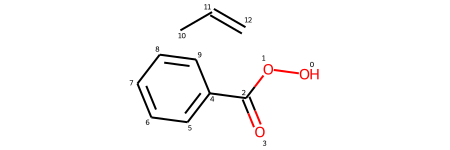

In [115]:
Chem.Draw.IPythonConsole.drawOptions.addAtomIndices = True
new_mols[1]

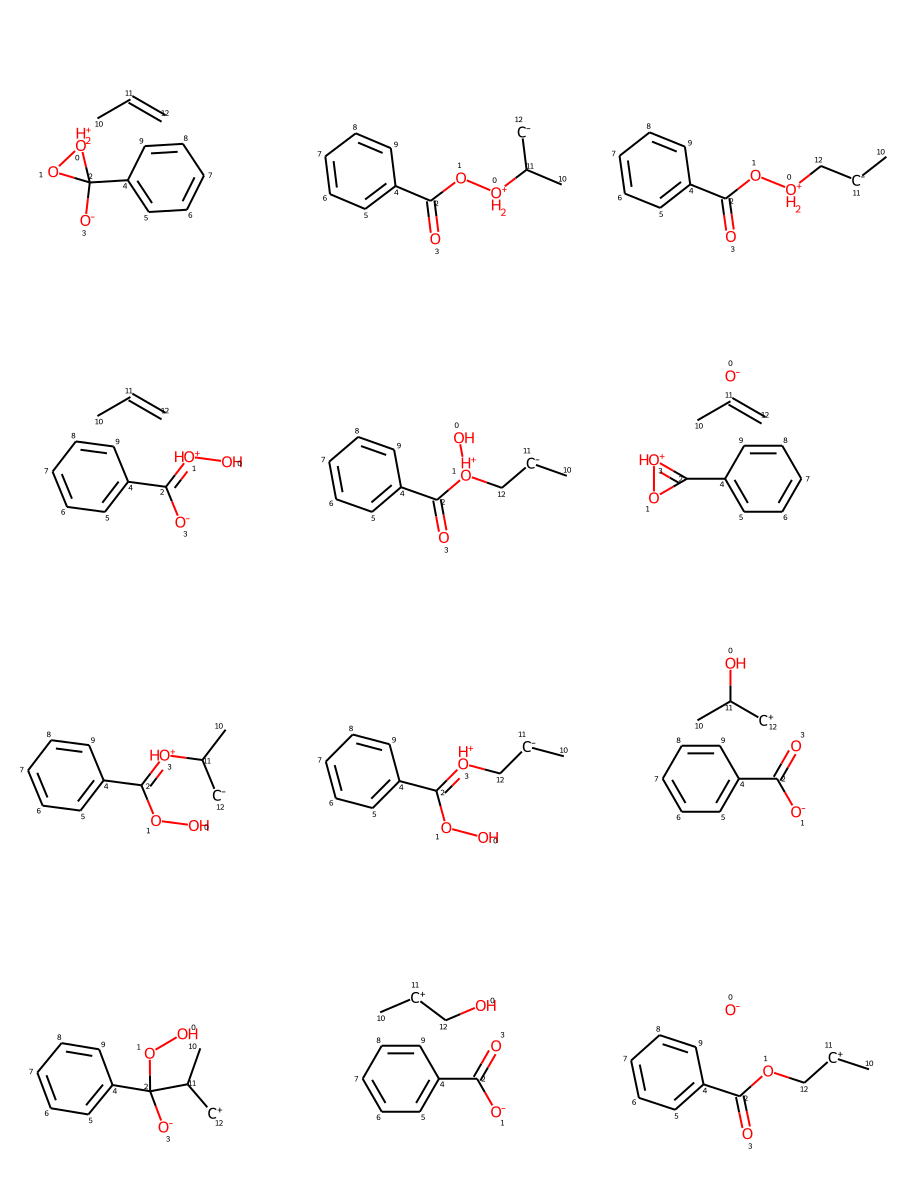

In [116]:
Chem.Draw.MolsToGridImage(connected_mols, molsPerRow=3, subImgSize=(300, 300))


In [117]:
for mol in connected_mols:
    print(Chem.MolToSmiles(mol))

C=CC.[O-]C1(c2ccccc2)O[OH+]1
[CH2-]C(C)[OH+]OC(=O)c1ccccc1
C[CH-]C[OH+]OC(=O)c1ccccc1
C=CC.[O-]C(=[O+]O)c1ccccc1
C[CH-]C[O+](O)C(=O)c1ccccc1
C=CC.[OH-].c1ccc(C2=[O+]O2)cc1
[CH2-]C(C)[O+]=C(OO)c1ccccc1
C[CH-]C[O+]=C(OO)c1ccccc1
O=C([O-])c1ccccc1.[CH2+]C(C)O
[CH2+]C(C)C([O-])(OO)c1ccccc1
C[CH+]CO.O=C([O-])c1ccccc1
C[CH+]COC(=O)c1ccccc1.[OH-]


In [28]:
Chem.MolToSmiles(connected_mols[0])

'[Br-].[CH2+]C(C)Br'

In [37]:
def write_reaction_smiles(mol1, mol2, product):
    with open ("reactions.txt", 'a', encoding='utf-8') as file:
        line = Chem.MolToSmiles(mol1) + "." + Chem.MolToSmiles(mol2) + ">>" + Chem.MolToSmiles(product)
        file.write(line +"\n")
    

In [111]:
for product in connected_mols:
    write_reaction_smiles(mol1, mol2, product)

In [17]:
Chem.MolToSmiles(inter_mol)

'C=C.[Br-].[BrH2+]'